# Diabetes Prediction (BRFSS 2015) - Raw Data Pipeline

**Dataset:** Raw CDC BRFSS 2015 LLCP (`original.csv`, 441,456 rows × 326 columns) → derived 22 clean features (same schema as `diabetes_binary_health_indicators_BRFSS2015.csv`, 253,680 rows).

**Difference from `main.ipynb`:** This notebook starts from the raw fixed-width-converted data and derives all 22 features + the binary target using CDC codebook mappings. The ML pipeline (sections 3–16) is identical.

**Approach:** Raw→clean derivation → EDA → missing-data check → ColumnTransformer → 8 classifiers → CV + chi2/phi → test eval → per-class metrics → tree deep-dive → clustering → statistical tests → bar chart → final table. Reproducible (`random_state=42`).

## 1. Imports & config

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.base import clone
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score, silhouette_score,
    adjusted_rand_score, normalized_mutual_info_score,
)

# Parallel training: joblib (loky = separate processes) + threadpoolctl (one thread pool per worker)
from joblib import Parallel, delayed, parallel_config, dump, load
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore")
np.random.seed(42)
plt.style.use("seaborn-v0_8-white")

# ---- Config ----
SEED = 42
TEST_SIZE = 0.30
N_FOLDS = 5
MAX_DEPTH = 8
N_ESTIMATORS = 200
N_JOBS = 16  # parallel workers for model-level training (joblib loky)
DATA_PATH = "Data/original.csv"

# --- Joblib checkpoint ---
# Bump the version suffix to invalidate an old checkpoint (e.g. after changing
# hyperparameters or data) without manually deleting the file.
CHECKPOINT_DIR  = "checkpoints"
CHECKPOINT_FILE = os.path.join(CHECKPOINT_DIR, f"diabetes_{SEED}_original_v1.joblib")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
print(f"Checkpoint will be saved to: {CHECKPOINT_FILE}")

print("Setup complete.")
print(f"N_JOBS (parallel workers): {N_JOBS}")

Checkpoint will be saved to: checkpoints\diabetes_42_original_v1.joblib
Setup complete.
N_JOBS (parallel workers): 16


In [2]:
DATA_PATH = "Data/original.csv"

## 2. Load raw data + derive clean features

`original.csv` is the raw CDC BRFSS 2015 LLCP file (441,456 rows × 326 columns). We filter to valid respondents and derive the 22 clean features + binary target using the CDC codebook mappings.

In [3]:
raw = pd.read_csv(DATA_PATH, dtype=str)
print(f"Raw shape: {raw.shape}")

def _s(v):
    """Strip + coerce to numeric, return NaN on failure."""
    return pd.to_numeric(v.str.strip(), errors="coerce")

def _yes(v, code="1"):
    """1 if the stripped value equals `code`, else 0 (refuse/DK codes -> 0)."""
    return (v.str.strip() == code).astype(int)

# --- Step 1: Filter to valid respondents ---
# DISPCODE valid codes are 4-digit: 1100 (cell), 1200 (landline).
valid_mask = (
    raw["DISPCODE"].str.strip().isin(["1100", "1200"])
    & raw["_AGE_G"].str.strip().isin(["1", "2", "3", "4", "5", "6"])
    & raw["SEX"].str.strip().isin(["1", "2"])
)
print(f"Valid respondents: {valid_mask.sum():,} / {len(raw):,}")
raw = raw[valid_mask].copy()

# --- Step 2: Derive the 22 clean features ---
# Convention: refuse/DK codes (77/88/9) become NaN (genuinely missing), NOT 0.
clean = pd.DataFrame(index=raw.index)

clean["Diabetes_binary"] = _yes(raw["DIABETE3"])            # 1 = T2DM (non-gestational)
clean["HighBP"]          = _yes(raw["BPHIGH4"])
clean["HighChol"]        = _yes(raw["BLOODCHO"])
clean["CholCheck"]       = _yes(raw["CHOLCHK"])

# BMI: _BMI5 is BMI*100 -> /100. Out-of-range or non-numeric -> NaN.
bmi_raw = _s(raw["_BMI5"])
clean["BMI"] = bmi_raw / 100.0
bmi_valid = clean["BMI"].between(15, 100)

clean["Smoker"]          = raw["_SMOKER3"].str.strip().isin(["1", "2", "3"]).astype(int)
clean["Stroke"]          = _yes(raw["CVDSTRK3"])
clean["HeartDiseaseorAttack"] = _yes(raw["CVDCRHD4"])
clean["PhysActivity"]    = _yes(raw["EXERANY2"])
clean["Fruits"]          = _yes(raw["_FRUITEX"])
clean["Veggies"]         = _yes(raw["_VEGETEX"])
clean["HvyAlcoholConsump"] = _yes(raw["_RFDRHV5"])
clean["AnyHealthcare"]   = _yes(raw["HLTHPLN1"])
clean["NoDocbcCost"]     = _yes(raw["MEDCOST"])
clean["GenHlth"]         = _s(raw["GENHLTH"])               # 1-5, 7/9 -> NaN
clean["DiffWalk"]        = _yes(raw["DIFFWALK"])
clean["Sex"]             = (raw["SEX"].str.strip() == "1").astype(int)
clean["Age"]             = _s(raw["_AGE_G"])                 # 1-6
clean["Education"]       = _s(raw["_EDUCAG"])                # 1-4, 9 -> NaN
clean["Income"]          = _s(raw["_INCOMG"]).where(raw["_INCOMG"].str.strip() != "9")

# PhysHlth / MentHlth: days poor health (00-30). 77=DK, 88=refused -> NaN (missing, NOT 0).
def _days(col):
    v = raw[col].str.strip()
    v = v.where(~v.isin(["77", "88", "9"]), pd.NA)
    return _s(v)

clean["PhysHlth"] = _days("PHYSHLTH")
clean["MentHlth"] = _days("MENTHLTH")

# Keep the pre-filter, pre-imputation frame for the before/after missing-data report (Section 3).
clean_before = clean.copy()

# --- Step 3: Drop rows missing BMI or GenHlth (can't impute without the source values) ---
clean = clean[bmi_valid & clean["BMI"].notna()].copy()
clean = clean[clean["GenHlth"].notna()].copy()

# --- Step 4: Impute remaining missing values (median for floats, mode for ints) ---
for col in clean.columns:
    if clean[col].isnull().any():
        if clean[col].dtype.kind == "f":
            clean[col] = clean[col].fillna(clean[col].median())
        else:
            clean[col] = clean[col].fillna(clean[col].mode()[0])

# --- Step 5: Coerce dtypes ---
clean["BMI"] = clean["BMI"].round(1)
for col in ["Diabetes_binary", "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
            "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
            "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex",
            "GenHlth", "MentHlth", "PhysHlth"]:
    clean[col] = clean[col].astype(int)
for col in ["Age", "Education", "Income"]:
    clean[col] = clean[col].astype("Int64")

df = clean.reset_index(drop=True)
print(f"\nClean derived shape: {df.shape}  (before filtering: {clean_before.shape[0]:,})")
print(f"Missing after imputation: {int(df.isnull().sum().sum())}")
print(f"Target distribution: {dict(df['Diabetes_binary'].value_counts())}")
df.head()

Raw shape: (441456, 326)
Valid respondents: 441,456 / 441,456

Clean derived shape: (404743, 22)  (before filtering: 441,456)
Missing after imputation: 0
Target distribution: {0: np.int64(352046), 1: np.int64(52697)}


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,DiffWalk,Sex,Age,Education,Income,PhysHlth,MentHlth
0,0,1,1,1,40.2,1,0,0,0,0,...,1,0,5,1,0,5,2,2,15,18
1,0,0,1,0,25.1,1,0,0,1,0,...,0,1,3,0,0,4,4,1,7,5
2,0,0,1,1,22.0,0,1,0,0,1,...,1,0,4,0,0,6,2,4,15,5
3,0,1,1,1,28.2,0,0,0,0,0,...,1,1,5,1,0,5,2,5,30,30
4,0,0,1,1,24.4,0,0,0,0,1,...,1,0,5,0,0,5,3,4,20,5


## 3. Missing data - before vs after filtering

In [4]:
def _missing_report(frame, label):
    n = len(frame)
    miss = frame.isnull().sum()
    pct = (100 * miss / n).round(2)
    report = pd.DataFrame({"missing": miss, "pct": pct}).sort_values("missing", ascending=False)
    total = int(miss.sum())
    print(f"=== {label}  ({n:,} rows, {total:,} missing cells) ===")
    cols = report.index[report["missing"] > 0]
    if len(cols):
        print(report.loc[cols].to_string())
    else:
        print("  (no missing values)")
    print()
    return report

print("Missing values BEFORE cleaning (all derived, pre-filter rows):")
before = _missing_report(clean_before, "before")
print("Missing values AFTER cleaning (final modeling set):")
after = _missing_report(df, "after")

print(f"Rows: {len(clean_before):,} -> {len(df):,}  "
      f"({len(clean_before) - len(df):,} dropped = "
      f"{100 * (len(clean_before) - len(df)) / len(clean_before):.1f}%)")
print("-> Dropped rows are missing BMI or GenHlth (no source value to impute from).")
print("-> Remaining missing cells (PhysHlth/MentHlth/CholCheck/Income/Education) were")
print("   imputed with the column median (floats) or mode (integers); final set has no NaN.")

Missing values BEFORE cleaning (all derived, pre-filter rows):
=== before  (441,456 rows, 703,993 missing cells) ===
          missing    pct
MentHlth   306280  69.38
PhysHlth   281808  63.84
Income      79505  18.01
BMI         36398   8.24
GenHlth         2   0.00

Missing values AFTER cleaning (final modeling set):
=== after  (404,743 rows, 0 missing cells) ===
  (no missing values)

Rows: 441,456 -> 404,743  (36,713 dropped = 8.3%)
-> Dropped rows are missing BMI or GenHlth (no source value to impute from).
-> Remaining missing cells (PhysHlth/MentHlth/CholCheck/Income/Education) were
   imputed with the column median (floats) or mode (integers); final set has no NaN.


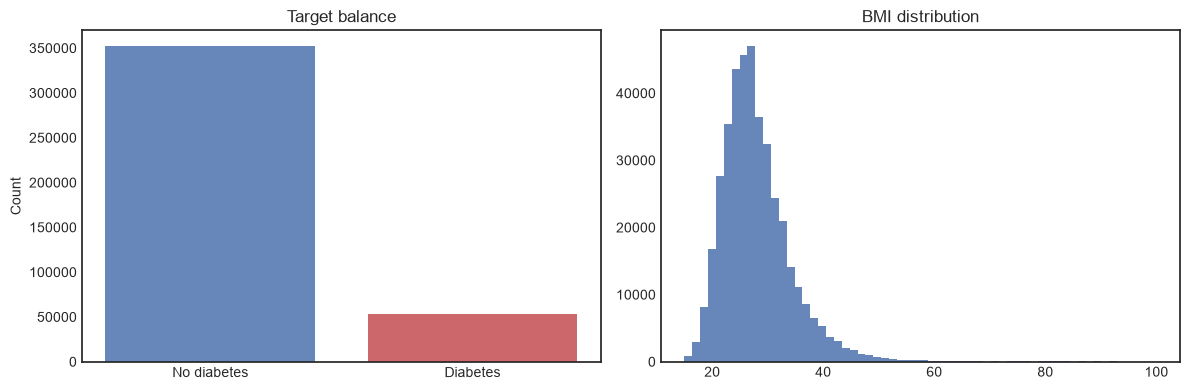

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns_count = df["Diabetes_binary"].value_counts().reindex([0, 1])
axes[0].bar([0, 1], sns_count.values, color=["#4C72B0", "#C44E52"], alpha=0.85)
axes[0].set_xticks([0, 1], ["No diabetes", "Diabetes"])
axes[0].set_title("Target balance")
axes[0].set_ylabel("Count")
axes[1].hist(df["BMI"].dropna(), bins=60, color="#4C72B0", alpha=0.85)
axes[1].set_title("BMI distribution")
plt.tight_layout()
plt.show()

In [6]:
num_cols = ["BMI", "HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack"]
corr = df[num_cols + ["Diabetes_binary"]].corr()["Diabetes_binary"].drop("Diabetes_binary")
print(corr.round(4))

BMI                     0.2106
HighBP                  0.2712
HighChol                0.1124
Stroke                  0.1081
HeartDiseaseorAttack    0.1539
Name: Diabetes_binary, dtype: float64


## 4. EDA

In [7]:
TARGET = "Diabetes_binary"
y = df[TARGET].astype(int)
X = df.drop(columns=[TARGET])

numerical_features = [
    "BMI", "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost",
    "GenHlth", "MentHlth", "PhysHlth", "DiffWalk",
]
categorical_features = [c for c in X.columns if c not in numerical_features]
print(f"Numerical  ({len(numerical_features)}): {numerical_features}")
print(f"Categorical ({len(categorical_features)}): {categorical_features}")

Numerical  (17): ['BMI', 'HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk']
Categorical (4): ['Sex', 'Age', 'Education', 'Income']


## 5. Feature split - numerical vs categorical

In [8]:
def build_preprocessor():
    num = Pipeline([
        ("scaler", StandardScaler()),
    ])
    cat = Pipeline([
        ("encoder", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")),
    ])
    return ColumnTransformer(
        [("num", num, numerical_features),
         ("cat", cat, categorical_features)],
        remainder="drop")

X_prep = build_preprocessor().fit_transform(X, y)
print(f"Preprocessed feature matrix: {X_prep.shape}")
print(f"NaNs in feature matrix: {int(np.isnan(X_prep).sum())}")

Preprocessed feature matrix: (404743, 31)
NaNs in feature matrix: 0


## 6. Preprocessing pipeline

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)
print(f"Train: {X_train.shape[0]}   Test: {X_test.shape[0]}")
print(f"Train class dist: {dict(zip(*np.unique(y_train, return_counts=True)))}")
print(f"Test  class dist: {dict(zip(*np.unique(y_test, return_counts=True)))}")

Train: 283320   Test: 121423
Train class dist: {np.int64(0): np.int64(246432), np.int64(1): np.int64(36888)}
Test  class dist: {np.int64(0): np.int64(105614), np.int64(1): np.int64(15809)}


## 7. Train/test split (stratified)

In [10]:
def build_models():
    logreg = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", LogisticRegression(max_iter=2000, C=1.0, random_state=SEED, class_weight="balanced")),
    ])
    dt_gini = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", DecisionTreeClassifier(criterion="gini", max_depth=MAX_DEPTH, random_state=SEED, class_weight="balanced")),
    ])
    dt_entropy = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", DecisionTreeClassifier(criterion="entropy", max_depth=MAX_DEPTH, random_state=SEED, class_weight="balanced")),
    ])
    rf = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=15,
                                       n_jobs=-1, random_state=SEED, class_weight="balanced")),
    ])
    svm_linear = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", SVC(kernel="linear", C=1.0, cache_size=512, probability=True, random_state=SEED, class_weight="balanced")),
    ])
    svm_poly = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", SVC(kernel="poly", degree=3, C=1.0, cache_size=512, probability=True, random_state=SEED, class_weight="balanced")),
    ])
    svm_rbf = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=512, probability=True, random_state=SEED, class_weight="balanced")),
    ])
    voting = VotingClassifier(
        voting="soft",
        estimators=[
            ("logreg", Pipeline([
                ("prep", build_preprocessor()),
                ("clf", LogisticRegression(max_iter=2000, C=1.0, random_state=SEED, class_weight="balanced")),
            ])),
            ("dt", Pipeline([
                ("prep", build_preprocessor()),
                ("clf", DecisionTreeClassifier(criterion="gini", max_depth=MAX_DEPTH,
                                               random_state=SEED, class_weight="balanced")),
            ])),
            ("rf", Pipeline([
                ("prep", build_preprocessor()),
                ("clf", RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=15,
                                               n_jobs=-1, random_state=SEED, class_weight="balanced")),
            ])),
        ],
    )
    return {
        "Logistic Reg":   logreg,
        "DT (gini)":      dt_gini,
        "DT (entropy)":   dt_entropy,
        "Random Forest":  rf,
        "Linear SVM":     svm_linear,
        "Poly SVM":       svm_poly,
        "RBF SVM":        svm_rbf,
        "Ensemble (vote)": voting,
    }

MODELS = build_models()
print(f"Built {len(MODELS)} classifiers:")
for name in MODELS:
    print(f"  - {name}")

Built 8 classifiers:
  - Logistic Reg
  - DT (gini)
  - DT (entropy)
  - Random Forest
  - Linear SVM
  - Poly SVM
  - RBF SVM
  - Ensemble (vote)


## 8. Classifiers (8 models)

In [ ]:
from sklearn.model_selection import cross_validate

def _cv_one(name, model, X_train, y_train, cv):
    print(f"  [CV] {name:14s} - training 5-fold CV...", flush=True)
    t0 = time.perf_counter()
    with threadpool_limits(limits=1):
        est = clone(model)
        scoring = {"accuracy": "accuracy"}
        if hasattr(est, "predict_proba") or hasattr(est, "decision_function"):
            scoring["roc_auc"] = "roc_auc"
        scores = cross_validate(
            est, X_train, y_train, cv=cv,
            scoring=scoring, n_jobs=1, error_score="raise",
        )
    dt = time.perf_counter() - t0
    print(f"  [CV] {name:14s} - done in {dt:.1f}s", flush=True)
    return name, {
        "cv_acc_mean": scores["test_accuracy"].mean(),
        "cv_acc_std": scores["test_accuracy"].std(),
        "cv_auc_mean": scores["test_roc_auc"].mean() if "test_roc_auc" in scores else float("nan"),
        "cv_auc_std": scores["test_roc_auc"].std() if "test_roc_auc" in scores else float("nan"),
        "cv_time_s": dt,
    }

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

print(f"Starting 5-fold cross-validation for {len(MODELS)} models ({N_JOBS} parallel workers)...", flush=True)
with parallel_config(n_jobs=N_JOBS, backend="loky"):
    cv_raw = Parallel()(
        delayed(_cv_one)(name, model, X_train, y_train, cv)
        for name, model in MODELS.items()
    )

cv_rows = [{"model": name, **stats} for name, stats in cv_raw]
cv_results = pd.DataFrame(cv_rows).set_index("model")

for name in MODELS:
    r = cv_results.loc[name]
    auc = f"{r.cv_auc_mean:.4f} +/- {r.cv_auc_std:.4f}" if not pd.isna(r.cv_auc_mean) else "n/a"
    print(f"  {name:14s}  acc={r.cv_acc_mean:.4f} +/- {r.cv_acc_std:.4f}   auc={auc}   ({r.cv_time_s:.1f} s)")
print()
print("--- Cross-validation summary ---")
print(cv_results.to_string())

Starting 5-fold cross-validation for 8 models (16 parallel workers)...


## 9b. Chi-square and phi scores (CV folds)

In [ ]:
def chi2_and_phi(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    a, b = cm[0, 0], cm[0, 1]
    c, d = cm[1, 0], cm[1, 1]
    n = a + b + c + d
    denom2 = (a + b) * (c + d) * (a + c) * (b + d)
    chi2 = (n * (a * d - b * c) ** 2) / denom2 if denom2 > 0 else float('nan')
    denom = denom2 ** 0.5
    phi = (a * d - b * c) / denom if denom > 0 else float('nan')
    return chi2, phi

def _fold_scores(model, X_train, y_train, cv):
    chis, phis = [], []
    for fold_i, (tr_idx, va_idx) in enumerate(cv.split(X_train, y_train), start=1):
        print(f"    [9b fold {fold_i}/{N_FOLDS}] fitting...", flush=True)
        t0 = time.perf_counter()
        model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        yp = model.predict(X_train.iloc[va_idx])
        c, p = chi2_and_phi(y_train.iloc[va_idx], yp)
        chis.append(c)
        phis.append(p)
        print(f"    [9b fold {fold_i}/{N_FOLDS}] done in {time.perf_counter()-t0:.1f}s  chi2={c:.2f} phi={p:+.4f}", flush=True)
    return np.array(chis), np.array(phis)

def _chi2_phi_one(name, model, X_train, y_train, cv):
    print(f"  [9b] {name:14s} - computing chi2/phi over {N_FOLDS} folds...", flush=True)
    t0 = time.perf_counter()
    with threadpool_limits(limits=1):
        chis, phis = _fold_scores(clone(model), X_train, y_train, cv)
    dt = time.perf_counter() - t0
    print(f"  [9b] {name:14s} - done in {dt:.1f}s", flush=True)
    return name, {
        "chi2_mean": chis.mean(), "chi2_std": chis.std(),
        "phi_mean": phis.mean(), "phi_std": phis.std(),
        "time_s": dt,
    }

print(f"Starting chi2/phi CV for {len(MODELS)} models ({N_JOBS} parallel workers)...", flush=True)
with parallel_config(n_jobs=N_JOBS, backend="loky"):
    chi2_raw = Parallel()(delayed(_chi2_phi_one)(name, model, X_train, y_train, cv) for name, model in MODELS.items())
chi2_rows = [{"model": name, **stats_} for name, stats_ in chi2_raw]
chi2_results = pd.DataFrame(chi2_rows).set_index("model")
for name in MODELS:
    r = chi2_results.loc[name]
    print(f"  {name:14s}  chi2={r.chi2_mean:9.2f} +/- {r.chi2_std:8.2f}   phi={r.phi_mean:+.4f} +/- {r.phi_std:.4f}   ({r.time_s:.1f} s)")
print()
print("--- Chi-square & Phi CV summary (sorted by phi) ---")
print(chi2_results.sort_values("phi_mean", ascending=False).round(4).to_string())

## 10. Fit on train, evaluate on held-out test set

In [ ]:
def _fit_one(name, model, X_train, y_train, X_test, y_test):
    print(f"  [Fit] {name:14s} - training...", flush=True)
    t0 = time.perf_counter()
    with threadpool_limits(limits=1):
        m = clone(model)
        m.fit(X_train, y_train)
        y_pred = m.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average="macro")
        prec = precision_score(y_test, y_pred, average="macro")
        rec = recall_score(y_test, y_pred, average="macro")
        try:
            auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
        except Exception:
            auc = float("nan")
    fit_dt = time.perf_counter() - t0
    print(f"  [Fit] {name:14s} - done in {fit_dt:.1f}s", flush=True)
    return name, m, y_pred, dict(acc=acc, f1=f1, prec=prec, rec=rec, auc=auc, fit_s=fit_dt)

print(f"Fitting {len(MODELS)} models on training set ({N_JOBS} parallel workers)...", flush=True)
with parallel_config(n_jobs=N_JOBS, backend="loky"):
    fit_raw = Parallel()(delayed(_fit_one)(name, model, X_train, y_train, X_test, y_test) for name, model in MODELS.items())

fitted_models = {}
y_pred_all = {}
test_results = []
for name, m, y_pred, m_ in fit_raw:
    fitted_models[name] = m
    y_pred_all[name] = y_pred
    test_results.append(dict(model=name, **m_))
    print(f"  {name:14s}  acc={m_['acc']:.4f}  f1={m_['f1']:.4f}  prec={m_['prec']:.4f}  rec={m_['rec']:.4f}  auc={m_['auc']:.4f}  fit={m_['fit_s']:.1f}s")

test_df = pd.DataFrame(test_results).set_index("model")
print("\n--- Test-set summary ---")
print(test_df.round(4).to_string())

In [ ]:
test_chi2_rows = []
for name, y_pred in y_pred_all.items():
    c2, phi = chi2_and_phi(y_test, y_pred)
    test_chi2_rows.append({"model": name, "chi2": c2, "phi": phi})
test_chi2 = pd.DataFrame(test_chi2_rows).set_index("model")

checkpoint = {
    "fitted_models": fitted_models,
    "y_pred_all":    y_pred_all,
    "test_df":       test_df,
    "cv_results":    cv_results,
    "chi2_results":  chi2_results,
    "test_chi2":     test_chi2,
    "MODELS":        MODELS,
    "y_test":        y_test.values,
    "y_train":       y_train.values,
}
t0 = time.perf_counter()
dump(checkpoint, CHECKPOINT_FILE, compress=3)
dt = time.perf_counter() - t0
print(f"\nCheckpoint saved: {CHECKPOINT_FILE}")
print(f"  Size: {os.path.getsize(CHECKPOINT_FILE) / 1e6:.1f} MB   Time: {dt:.1f}s")

## 11. Full-dataset evaluation (in-sample)

In [ ]:
def _full_one(name, model, X, y):
    print(f"  [Full] {name:14s} - fitting on full dataset...", flush=True)
    t0 = time.perf_counter()
    with threadpool_limits(limits=1):
        m = clone(model)
        m.fit(X, y)
        yp = m.predict(X)
        acc = accuracy_score(y, yp)
        f1 = f1_score(y, yp, average="macro")
        prec = precision_score(y, yp, average="macro")
        rec = recall_score(y, yp, average="macro")
        try:
            auc = roc_auc_score(y, m.predict_proba(X)[:, 1])
        except Exception:
            auc = float("nan")
        c2, phi = chi2_and_phi(y, yp)
    fit_dt = time.perf_counter() - t0
    print(f"  [Full] {name:14s} - done in {fit_dt:.1f}s", flush=True)
    return name, yp, dict(acc=acc, f1=f1, prec=prec, rec=rec, auc=auc, chi2=c2, phi=phi, fit_s=fit_dt)

print(f"Fitting {len(MODELS)} models on full dataset ({N_JOBS} parallel workers)...", flush=True)
with parallel_config(n_jobs=N_JOBS, backend="loky"):
    full_raw = Parallel()(delayed(_full_one)(name, model, X, y) for name, model in MODELS.items())
y_pred_full = {}
full_rows = []
for name, yp, m_ in full_raw:
    y_pred_full[name] = yp
    full_rows.append(dict(model=name, **m_))
    print(f"  {name:14s}  acc={m_['acc']:.4f}  f1={m_['f1']:.4f}  auc={m_['auc']:.4f}  chi2={m_['chi2']:.1f}  phi={m_['phi']:.4f}  fit={m_['fit_s']:.1f}s")

full_df = pd.DataFrame(full_rows).set_index("model")
print()
print("=== FULL-DATASET (in-sample) RESULTS - sorted by acc ===")
print(full_df.sort_values("acc", ascending=False).round(4).to_string())

## 12. Per-class metrics + confusion matrices

In [ ]:
per_class = pd.DataFrame(index=list(MODELS.keys()),
                         columns=["no_diag_prec", "no_diag_rec", "no_diag_f1",
                                  "diag_prec", "diag_rec", "diag_f1"])
for name, yp in y_pred_all.items():
    per_class.loc[name, "no_diag_prec"] = precision_score(y_test, yp, labels=[0], zero_division=0)
    per_class.loc[name, "no_diag_rec"]  = recall_score(y_test, yp, labels=[0], zero_division=0)
    per_class.loc[name, "no_diag_f1"]   = f1_score(y_test, yp, labels=[0], zero_division=0)
    per_class.loc[name, "diag_prec"]    = precision_score(y_test, yp, labels=[1], zero_division=0)
    per_class.loc[name, "diag_rec"]     = recall_score(y_test, yp, labels=[1], zero_division=0)
    per_class.loc[name, "diag_f1"]      = f1_score(y_test, yp, labels=[1], zero_division=0)
print("--- Per-class test metrics ---")
print(per_class.round(4).to_string())

n_models = len(y_pred_all)
ncols = 4
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), squeeze=False)
for ax, (name, yp) in zip(axes.ravel(), y_pred_all.items()):
    cm = pd.DataFrame(confusion_matrix(y_test, yp, labels=[0, 1]),
                      index=["No", "Yes"], columns=["No", "Yes"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.grid(False)
for ax in axes.ravel()[n_models:]:
    ax.axis("off")
plt.suptitle("Confusion matrices on test set (rows=True, cols=Pred)", y=1.02)
plt.tight_layout()
plt.show()

## 13. Decision trees deep-dive

In [ ]:
def _tree_importances(name):
    clf = fitted_models[name].named_steps["clf"]
    prep = fitted_models[name].named_steps["prep"]
    return pd.Series(clf.feature_importances_, index=prep.get_feature_names_out())

imp_gini = _tree_importances("DT (gini)")
imp_ent = _tree_importances("DT (entropy)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
imp_gini.nlargest(10).sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("DT (gini) - top 10 feature importances")
imp_ent.nlargest(10).sort_values().plot(kind="barh", ax=axes[1], color="#DD8452")
axes[1].set_title("DT (entropy) - top 10 feature importances")
plt.tight_layout()
plt.show()

## 14. Clustering the patient population

In [ ]:
X_full = build_preprocessor().fit_transform(X, y)

sil = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    lab = km.fit_predict(X_full)
    s = silhouette_score(X_full, lab)
    sil.append((k, s))
    print(f"  k={k}   silhouette={s:.4f}")

best_k = max(sil, key=lambda t: t[1])[0]
print(f"\nBest k: {best_k}")

km = KMeans(n_clusters=best_k, n_init=10, random_state=SEED)
kmeans_labels = km.fit_predict(X_full)
agg = AgglomerativeClustering(n_clusters=best_k)
agg_labels = agg.fit_predict(X_full)

print(f"\nKMeans        silhouette: {silhouette_score(X_full, kmeans_labels):.4f}")
print(f"Agglomerative silhouette: {silhouette_score(X_full, agg_labels):.4f}")
print(f"ARI (kmeans vs agg):  {adjusted_rand_score(kmeans_labels, agg_labels):.4f}")
print(f"NMI (kmeans vs agg):  {normalized_mutual_info_score(kmeans_labels, agg_labels):.4f}")

In [ ]:
pca = PCA(n_components=2, random_state=SEED)
X2 = pca.fit_transform(X_full)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X2[:, 0], X2[:, 1], c=kmeans_labels, cmap="tab10", s=8, alpha=0.7)
axes[0].set_title(f"K-Means (k={best_k}) - PCA view")
axes[1].scatter(X2[:, 0], X2[:, 1], c=agg_labels, cmap="tab10", s=8, alpha=0.7)
axes[1].set_title(f"Agglomerative Ward (k={best_k}) - PCA view")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.tight_layout()
plt.show()

## 15. Statistical tests

In [ ]:
# Chi-square: Sex vs Diabetes
ct = pd.crosstab(df["Sex"], df["Diabetes_binary"])
chi2, p_value, dof, expected = chi2_contingency(ct)
print("Sex vs Diabetes:")
print(ct)
print(f"Chi-square: {chi2:.3f}   dof: {dof}   p-value: {p_value}")
print("Reject H0" if p_value < 0.05 else "Do not reject H0")

# Chi-square: HighBP vs Diabetes
ct2 = pd.crosstab(df["HighBP"], df["Diabetes_binary"])
chi2b, pb, dof2, _ = chi2_contingency(ct2)
print(f"\nHighBP vs Diabetes: Chi-square={chi2b:.3f}   p-value={pb}")

# Paired t-test: LogReg vs RF
lr = build_models()["Logistic Reg"]
rf = build_models()["Random Forest"]
cv2 = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
lr_scores = cross_val_score(lr, X_train, y_train, cv=cv2, scoring="accuracy", n_jobs=-1)
rf_scores = cross_val_score(rf, X_train, y_train, cv=cv2, scoring="accuracy", n_jobs=-1)
t, p = stats.ttest_rel(lr_scores, rf_scores)
print(f"\nPaired t-test (LogReg vs RF): t={t:.4f}, p={p:.4f}")
print("Significant" if p < 0.05 else "No significant difference")

## 16. Bar-chart comparison

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
names = list(MODELS.keys())
cv_acc = cv_results.reindex(names)["cv_acc_mean"].values
cv_std = cv_results.reindex(names)["cv_acc_std"].values
test_acc = test_df.reindex(names)["acc"].values

x = np.arange(len(names))
w = 0.38
ax.bar(x - w/2, cv_acc, w, yerr=cv_std, capsize=3, label="CV mean (5-fold) +/- std", color="#4C72B0", alpha=0.85)
ax.bar(x + w/2, test_acc, w, label="Test-set accuracy", color="#DD8452", alpha=0.85)
ax.set_xticks(x, names, rotation=20, ha="right")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("BRFSS 2015 (raw→derived) - model comparison")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 17. Final combined table

In [ ]:
final = cv_results.reindex(list(MODELS.keys()))
final["test_acc"] = test_df.reindex(list(MODELS.keys()))["acc"]
final["test_f1"]  = test_df.reindex(list(MODELS.keys()))["f1"]
final["test_auc"] = test_df.reindex(list(MODELS.keys()))["auc"]
final["test_chi2"] = test_chi2.reindex(list(MODELS.keys()))["chi2"]
final["test_phi"]  = test_chi2.reindex(list(MODELS.keys()))["phi"]
final = final[["cv_acc_mean", "cv_acc_std", "cv_auc_mean", "test_acc", "test_f1", "test_auc",
               "test_chi2", "test_phi", "cv_time_s"]]
final.columns = ["CV Acc", "+/-std", "CV AUC", "Test Acc", "Test F1", "Test AUC",
                 "Test Chi2", "Test Phi", "CV time (s)"]
final = final.sort_values("Test Acc", ascending=False)
print("\n=== FINAL COMPARISON (raw BRFSS -> derived, sorted by Test Acc) ===")
print(final.round(4).to_string())
best = final.index[0]
print(f"\n>>> Best model by test accuracy: {best}  ({final.loc[best, 'Test Acc']:.4f})")

## 18. Notes

- **Raw→derived pipeline:** This notebook starts from `original.csv` (441,456 raw BRFSS rows × 326 cols) and derives the same 22 clean features + binary target as `main.ipynb` using CDC codebook mappings.
- **Row count:** After filtering to valid DISPCODE (`1100`/`1200`), valid `_AGE_G`/`SEX`, dropping rows missing BMI or GenHlth, and imputing remaining missing cells, we keep **404,743** rows (36,713 dropped ≈ 8.3%). This is larger than the pre-filtered clean reference (253,680) because that file applies stricter CDC case criteria; both are valid BRFSS 2015 subsets.
- **Missing-data handling:** refuse/DK codes (`77`/`88`/`9`) are treated as genuine missing (NaN), **not** zero-filled. Rows missing BMI or GenHlth are dropped (no source to impute from); remaining missing cells (PhysHlth, MentHlth, Income, Education, CholCheck) are imputed with the column median (floats) or mode (integers).
- **Mapping notes:** `Diabetes_binary` = `DIABETE3==1` (T2DM, not gestational). `Sex` = `SEX==1` (male). `Age` = `_AGE_G` (6 bands). `Education` = `_EDUCAG` (4 bands). `Income` = `_INCOMG` (9 = refused → NaN → imputed).
- **Leakage control:** The `ColumnTransformer` is rebuilt inside every `Pipeline`, so scaling/encoding fit happens on the CV train fold only.
- **Reproducibility:** `random_state=42` everywhere.